# Лабораторная работа №4. Бинарная классификация

**Цель:** построить модели бинарной классификации на основе логистической регрессии, метода опорных векторов (SVM) и дерева решений (CART), подготовить данные и сравнить качество моделей.

**План:**
1. Импорт датасета для бинарной классификации
2. Анализ и очистка данных (пропуски, дубликаты, выбросы)
3. Целевая переменная и набор признаков (разбиение, обработка выбросов, отбор признаков, стандартизация)
4. Модели: логистическая регрессия (своя реализация и `sklearn`), SVM, CART
5. Оценка качества моделей и сравнение
6. Выводы

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, classification_report)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
plt.rcParams['figure.figsize'] = (8, 5)
sns.set_style('whitegrid')

## 1. Импорт датасета

Используется учебный набор данных `load_breast_cancer` из `sklearn` (диагностика рака молочной железы по характеристикам клеточных ядер, полученным из оцифрованных изображений). Задача – бинарная классификация: опухоль **злокачественная** или **доброкачественная**.

В `sklearn` метки закодированы так: 0 – злокачественная, 1 – доброкачественная. Для удобства интерпретации метрик переопределим целевой признак: **1 – злокачественная опухоль** (положительный класс, который важнее всего не пропустить), 0 – доброкачественная.

In [ ]:
bunch = load_breast_cancer(as_frame=True)
df = bunch.frame.copy()

# 1 - злокачественная (положительный класс), 0 - доброкачественная
df['malignant'] = 1 - df['target']
df = df.drop(columns='target')

print('Размер набора данных:', df.shape)
df.head()

Размер набора данных: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,malignant
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [ ]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


malignant
0    357
1    212
Name: count, dtype: int64
Доля злокачественных: 0.373


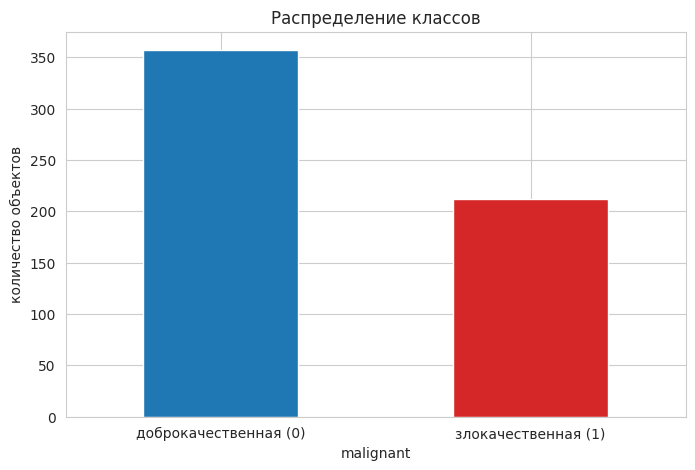

In [ ]:
counts = df['malignant'].value_counts().sort_index()
print(counts)
print('Доля злокачественных:', round(counts[1] / len(df), 3))

ax = counts.rename({0: 'доброкачественная (0)', 1: 'злокачественная (1)'}).plot(kind='bar', color=['tab:blue', 'tab:red'], rot=0)
ax.set_title('Распределение классов')
ax.set_ylabel('количество объектов')
plt.show()

Классы умеренно несбалансированы (примерно 63% / 37%), поэтому помимо `accuracy` будем использовать `precision`, `recall`, `F1` и `ROC-AUC`.

## 2. Анализ и очистка данных

### 2.1 Пропущенные значения и дубликаты

In [ ]:
print('Всего пропусков:', int(df.isna().sum().sum()))
print('Дубликатов строк:', int(df.duplicated().sum()))
print('Нечисловых признаков:', int((df.dtypes == 'object').sum()))

Всего пропусков: 0
Дубликатов строк: 0
Нечисловых признаков: 0


In [ ]:
# Очистка: удаляем дубликаты (если есть). Пропуски (если бы они были) заполняются медианой по обучающей выборке
# на этапе подготовки признаков (раздел 3) - это исключает утечку информации из тестовой выборки.
df = df.drop_duplicates().reset_index(drop=True)
print('Размер после удаления дубликатов:', df.shape)

Размер после удаления дубликатов: (569, 31)


Пропусков, дубликатов и категориальных признаков нет: все 30 признаков числовые, данные готовы к работе. Код для заполнения пропусков медианой всё равно предусмотрен в разделе 3, чтобы пайплайн работал и на других наборах данных.

### 2.2 Выбросы

Для поиска выбросов используем правило межквартильного размаха (IQR): значение считается выбросом, если оно выходит за границы $[Q_1 - 1.5\cdot IQR,\; Q_3 + 1.5\cdot IQR]$.

In [ ]:
features_all = [c for c in df.columns if c != 'malignant']

def iqr_bounds(frame, k=1.5):
    q1, q3 = frame.quantile(0.25), frame.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

lo, hi = iqr_bounds(df[features_all])
outliers = ((df[features_all] < lo) | (df[features_all] > hi))

out_stat = pd.DataFrame({'выбросов': outliers.sum(), 'доля, %': (outliers.mean() * 100).round(2)})
print('Строк, содержащих хотя бы один выброс:', int(outliers.any(axis=1).sum()), 'из', len(df))
out_stat.sort_values('выбросов', ascending=False).head(10)

Строк, содержащих хотя бы один выброс: 171 из 569


,выбросов,"доля, %"
area error,65,11.42
radius error,38,6.68
perimeter error,38,6.68
worst area,35,6.15
smoothness error,30,5.27
fractal dimension error,28,4.92
compactness error,28,4.92
symmetry error,27,4.75
mean area,25,4.39
worst fractal dimension,24,4.22


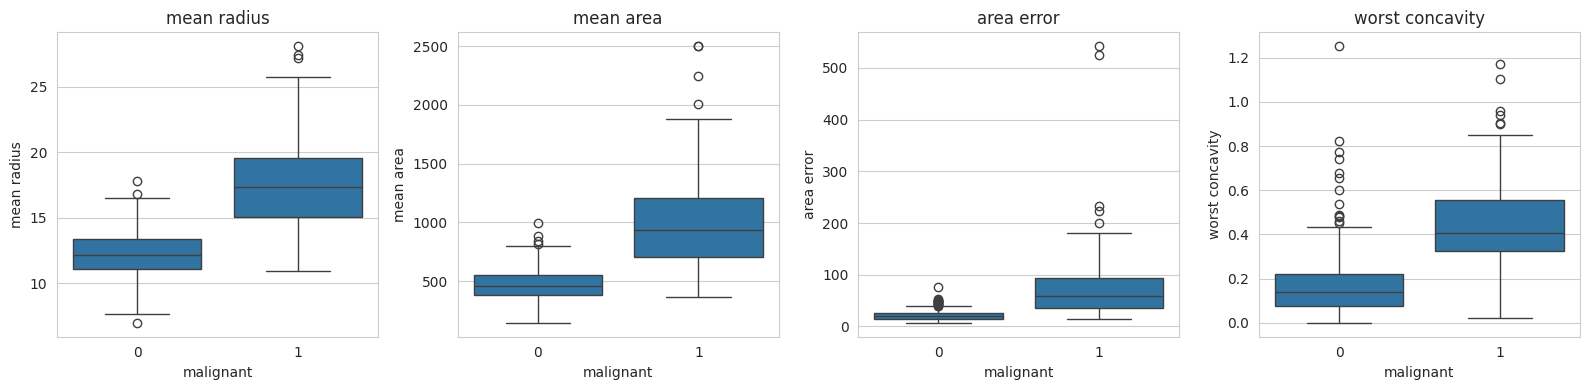

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ['mean radius', 'mean area', 'area error', 'worst concavity']):
    sns.boxplot(data=df, x='malignant', y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

Выбросов довольно много, причём они сосредоточены в основном у злокачественного класса (крупные опухоли с большими значениями размера и площади). Это не ошибки измерений, а реальные клинические случаи, поэтому **удалять такие строки нельзя**: мы потеряли бы часть положительного класса. Вместо этого выбросы будут **ограничены (winsorization)** по границам IQR, вычисленным **только по обучающей выборке** (раздел 3). Это уменьшает влияние экстремальных значений на логистическую регрессию и SVM, чувствительные к масштабу признаков.

### 2.3 Корреляции между признаками

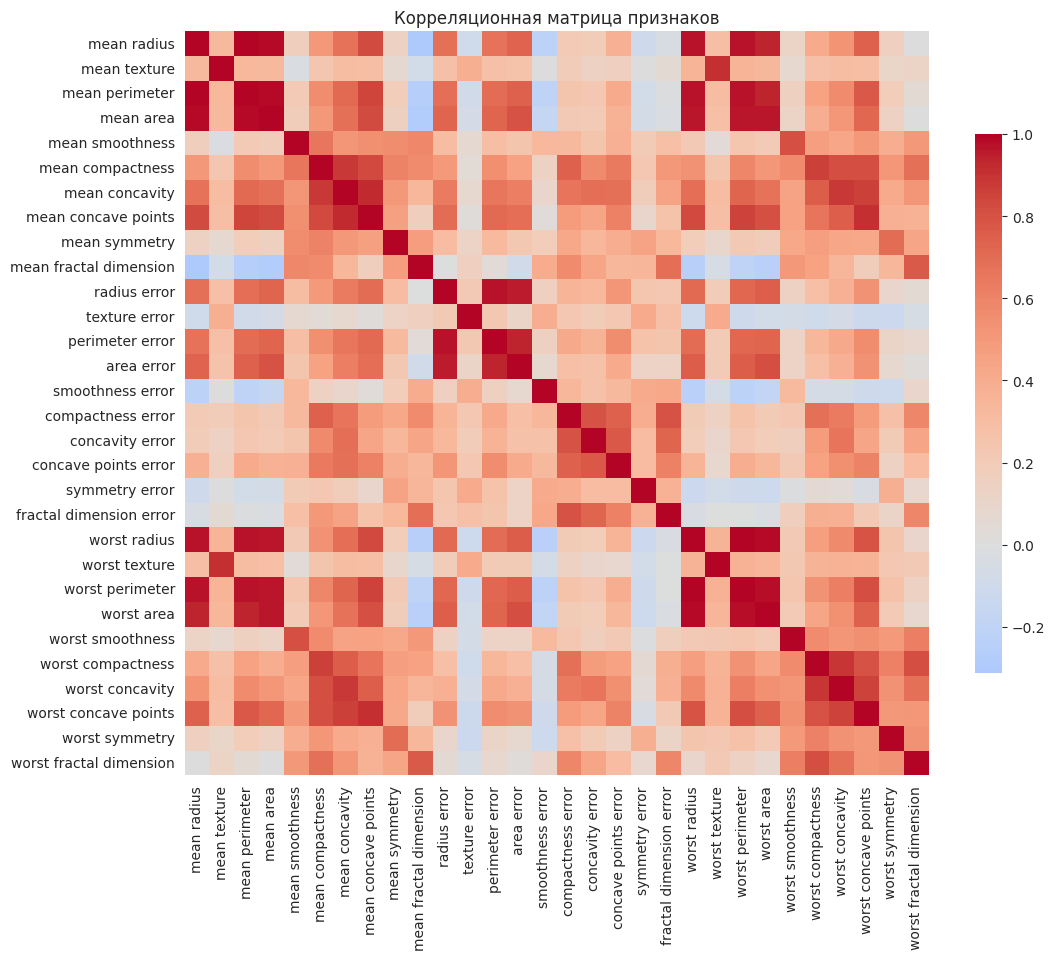

worst concave points    0.794
worst perimeter         0.783
mean concave points     0.777
worst radius            0.776
mean perimeter          0.743
worst area              0.734
mean radius             0.730
mean area               0.709
dtype: float64


In [ ]:
corr = df[features_all].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap='coolwarm', center=0, square=True, cbar_kws={'shrink': .7})
plt.title('Корреляционная матрица признаков')
plt.show()

# Корреляция признаков с целевой переменной
target_corr = df[features_all].corrwith(df['malignant']).sort_values(key=np.abs, ascending=False)
print(target_corr.head(8).round(3))

Многие признаки сильно коррелируют между собой (например, радиус, периметр и площадь – это функции одной и той же величины). Мультиколлинеарность не мешает дереву решений, но ухудшает обусловленность и интерпретируемость логистической регрессии, поэтому при формировании признаков избыточные признаки будут отброшены (из пары коррелирующих признаков остаётся более информативный).

## 3. Целевая переменная и набор признаков

- **Целевая переменная:** `malignant` (1 – злокачественная, 0 – доброкачественная).
- **Признаки:** 30 числовых характеристик ядер клеток (среднее, стандартная ошибка и «худшее» значение для 10 измеряемых величин).

Порядок подготовки (все параметры вычисляются **только по обучающей выборке**, чтобы не было утечки данных):
1. стратифицированное разбиение на обучающую (75%) и тестовую (25%) выборки;
2. заполнение пропусков медианой (если бы они были);
3. ограничение выбросов по границам IQR;
4. отбор признаков: из каждой группы сильно коррелирующих признаков ($|r| > 0.9$) оставляется тот, что сильнее связан с целевой переменной;
5. стандартизация (`StandardScaler`).

In [ ]:
X = df[features_all]
y = df['malignant']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)
print('train:', X_train.shape, ' test:', X_test.shape)
print('Доля класса 1: train =', round(y_train.mean(), 3), ' test =', round(y_test.mean(), 3))

train: (426, 30)  test: (143, 30)
Доля класса 1: train = 0.373  test = 0.371


In [ ]:
# 1) пропуски: медиана по обучающей выборке
medians = X_train.median()
X_train_p = X_train.fillna(medians)
X_test_p = X_test.fillna(medians)

# 2) выбросы: ограничение по границам IQR из обучающей выборки
lo_tr, hi_tr = iqr_bounds(X_train_p)
X_train_p = X_train_p.clip(lower=lo_tr, upper=hi_tr, axis=1)
X_test_p = X_test_p.clip(lower=lo_tr, upper=hi_tr, axis=1)

n_clipped = int(((X_train < lo_tr) | (X_train > hi_tr)).sum().sum())
print('Ограничено значений в обучающей выборке:', n_clipped)

Ограничено значений в обучающей выборке: 472


In [ ]:
# 3) отбор признаков: идём от признаков, сильнее всего связанных с целью, и оставляем признак,
#    только если он не коррелирует (|r| <= 0.9) с уже отобранными. Так из пары коррелирующих
#    признаков сохраняется более информативный.
corr_tr = X_train_p.corr().abs()
rank = X_train_p.corrwith(y_train).abs().sort_values(ascending=False).index

selected = []
for col in rank:
    if all(corr_tr.loc[col, kept] <= 0.9 for kept in selected):
        selected.append(col)
to_drop = [c for c in features_all if c not in selected]

print(f'Удалено признаков: {len(to_drop)}, осталось: {len(selected)}')
print('Удалены:', to_drop)
print('Оставлены (по убыванию связи с целью):', selected)
# 4) стандартизация
scaler = StandardScaler().fit(X_train_p[selected])
X_train_s = pd.DataFrame(scaler.transform(X_train_p[selected]), columns=selected, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test_p[selected]), columns=selected, index=X_test.index)

print('Максимальное |среднее| признаков (train):', round(float(X_train_s.mean().abs().max()), 6))
print('Стандартное отклонение признаков (train):', sorted(set(X_train_s.std(ddof=0).round(3))))

Xtr, Xte = X_train_s.values, X_test_s.values
ytr, yte = y_train.values, y_test.values

Удалено признаков: 12, осталось: 18
Удалены: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean concavity', 'radius error', 'perimeter error', 'compactness error', 'worst radius', 'worst area', 'worst compactness', 'worst concave points']
Оставлены (по убыванию связи с целью): ['worst perimeter', 'mean concave points', 'area error', 'worst concavity', 'mean compactness', 'worst texture', 'concave points error', 'worst smoothness', 'worst symmetry', 'mean smoothness', 'concavity error', 'mean symmetry', 'worst fractal dimension', 'fractal dimension error', 'symmetry error', 'smoothness error', 'mean fractal dimension', 'texture error']
Максимальное |среднее| признаков (train): 0.0
Стандартное отклонение признаков (train): [1.0]


In [ ]:
# Вспомогательные функции для оценки качества
results = {}

def calc_scores(y_true, y_pred, y_score):
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred),
        'recall': recall_score(y_true, y_pred),
        'f1': f1_score(y_true, y_pred),
        'roc_auc': roc_auc_score(y_true, y_score),
    }

def register(name, pred_train, score_train, pred_test, score_test):
    results[name] = {
        'train': calc_scores(ytr, pred_train, score_train),
        'test': calc_scores(yte, pred_test, score_test),
        'y_pred_test': np.asarray(pred_test),
        'y_score_test': np.asarray(score_test),
    }
    t = results[name]['test']
    print(f"{name}: test accuracy={t['accuracy']:.3f}, precision={t['precision']:.3f}, "
          f"recall={t['recall']:.3f}, F1={t['f1']:.3f}, ROC-AUC={t['roc_auc']:.3f}")

## 4. Модели бинарной классификации

### 4.1 Логистическая регрессия

#### Собственная реализация

Логистическая регрессия моделирует вероятность принадлежности к классу 1 с помощью сигмоиды:
$$\sigma(z) = \frac{1}{1 + e^{-z}}, \quad z = \langle w, x \rangle.$$
Веса находятся минимизацией логарифмической функции потерь (log loss):
$$L(w) = -\frac{1}{m}\sum_{i=1}^{m}\left(y_i \ln \sigma_i + (1-y_i)\ln(1-\sigma_i)\right), \qquad \nabla L = \frac{1}{m}X^T(\sigma - y),$$
методом градиентного спуска $w \leftarrow w - \eta \nabla L$. Объект относится к классу 1, если $\sigma > 0.5$.

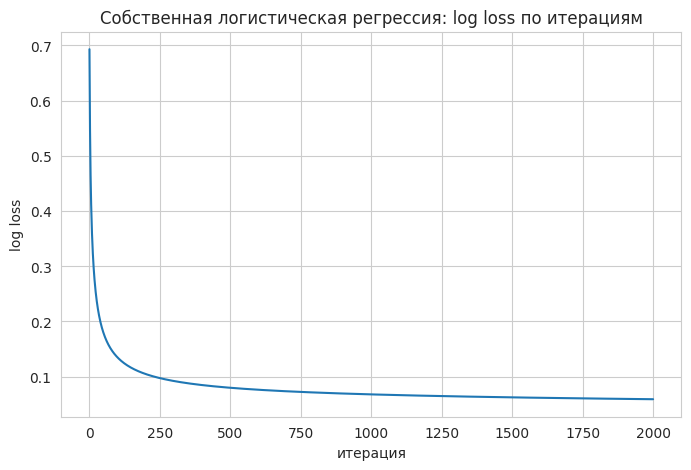

Итоговый log loss: 0.0591
LogReg (своя): test accuracy=0.986, precision=1.000, recall=0.962, F1=0.981, ROC-AUC=0.998


In [ ]:
def sigmoid(z):
    z = np.clip(z, -500, 500)          # защита от переполнения
    return 1.0 / (1.0 + np.exp(-z))

def log_loss(w, X, y):
    m = X.shape[0]
    A = sigmoid(X @ w)
    eps = 1e-12
    loss = -1.0 / m * np.sum(y * np.log(A + eps) + (1 - y) * np.log(1 - A + eps))
    grad = 1.0 / m * X.T @ (A - y)
    return loss, grad

def optimize(w, X, y, n_iterations, eta):
    losses = []
    for _ in range(n_iterations):
        loss, grad = log_loss(w, X, y)
        w = w - eta * grad
        losses.append(loss)
    return w, losses

def predict_proba_own(w, X):
    return sigmoid(X @ w)

def predict_own(w, X, threshold=0.5):
    return (predict_proba_own(w, X) > threshold).astype(int)

# добавляем столбец единиц для свободного члена
Xtr_b = np.hstack([np.ones((Xtr.shape[0], 1)), Xtr])
Xte_b = np.hstack([np.ones((Xte.shape[0], 1)), Xte])

w0 = np.zeros(Xtr_b.shape[1])
w_own, losses = optimize(w0, Xtr_b, ytr, n_iterations=2000, eta=0.1)

plt.plot(losses)
plt.title('Собственная логистическая регрессия: log loss по итерациям')
plt.xlabel('итерация'); plt.ylabel('log loss')
plt.show()
print('Итоговый log loss:', round(losses[-1], 4))

register('LogReg (своя)',
         predict_own(w_own, Xtr_b), predict_proba_own(w_own, Xtr_b),
         predict_own(w_own, Xte_b), predict_proba_own(w_own, Xte_b))

#### Логистическая регрессия из `sklearn` (подбор коэффициента регуляризации `C`)

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid_lr = GridSearchCV(
    LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
    param_grid={'C': [0.001, 0.01, 0.1, 1, 10, 100]},
    scoring='f1', cv=cv
)
grid_lr.fit(Xtr, ytr)
print('Лучшие параметры:', grid_lr.best_params_, ' F1 (CV):', round(grid_lr.best_score_, 4))

lr = grid_lr.best_estimator_
register('LogReg (sklearn)',
         lr.predict(Xtr), lr.decision_function(Xtr),
         lr.predict(Xte), lr.decision_function(Xte))

Лучшие параметры: {'C': 0.1}  F1 (CV): 0.9536
LogReg (sklearn): test accuracy=0.979, precision=1.000, recall=0.943, F1=0.971, ROC-AUC=0.998


In [ ]:
# Сравнение весов собственной и sklearn-реализации
pd.DataFrame({'своя': w_own[1:], 'sklearn': lr.coef_[0]}, index=selected).round(3).sort_values('sklearn', key=np.abs, ascending=False).head(10)

,своя,sklearn
area error,2.518,1.014
worst perimeter,1.914,0.935
worst texture,1.915,0.837
mean concave points,1.696,0.789
worst concavity,1.021,0.504
worst symmetry,0.981,0.442
mean fractal dimension,-0.602,-0.392
worst smoothness,0.637,0.346
fractal dimension error,-0.905,-0.322
concave points error,0.667,0.298


### 4.2 Метод опорных векторов (SVM)

SVM ищет разделяющую гиперплоскость с максимальным зазором между классами; для нелинейных границ используются ядра. Параметр `C` задаёт баланс между шириной зазора и числом ошибок, `gamma` – «радиус влияния» объектов в ядре RBF. SVM чувствителен к масштабу признаков, поэтому стандартизация выше обязательна.

Сначала сравним разные ядра при параметрах по умолчанию (кросс-валидация на обучающей выборке).

In [ ]:
kernel_cv = {}
for kernel in ['linear', 'rbf', 'poly', 'sigmoid']:
    scores = cross_val_score(SVC(kernel=kernel, random_state=RANDOM_STATE), Xtr, ytr, cv=cv, scoring='f1')
    kernel_cv[kernel] = scores
    print(f'{kernel:8s} F1 (CV) = {scores.mean():.4f} ± {scores.std():.4f}')

linear   F1 (CV) = 0.9490 ± 0.0277
rbf      F1 (CV) = 0.9645 ± 0.0120
poly     F1 (CV) = 0.8087 ± 0.0636
sigmoid  F1 (CV) = 0.8407 ± 0.0498


In [ ]:
param_grid_svm = {
    'kernel': ['linear', 'rbf'],
    'C': [0.01, 0.1, 1, 10, 100],
    'gamma': ['scale', 0.001, 0.01, 0.1],
}
grid_svm = GridSearchCV(SVC(random_state=RANDOM_STATE), param_grid_svm, scoring='f1', cv=cv, n_jobs=-1)
grid_svm.fit(Xtr, ytr)
print('Лучшие параметры:', grid_svm.best_params_, ' F1 (CV):', round(grid_svm.best_score_, 4))

svm = grid_svm.best_estimator_
print('Число опорных векторов:', svm.n_support_.sum(), 'из', len(ytr))

register('SVM (подбор)',
         svm.predict(Xtr), svm.decision_function(Xtr),
         svm.predict(Xte), svm.decision_function(Xte))

Лучшие параметры: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}  F1 (CV): 0.9717
Число опорных векторов: 82 из 426
SVM (подбор): test accuracy=0.972, precision=0.980, recall=0.943, F1=0.962, ROC-AUC=0.996


In [ ]:
# Для сравнения: SVM с ядрами по умолчанию
svm_lin = SVC(kernel='linear', random_state=RANDOM_STATE).fit(Xtr, ytr)
register('SVM linear (C=1)', svm_lin.predict(Xtr), svm_lin.decision_function(Xtr),
         svm_lin.predict(Xte), svm_lin.decision_function(Xte))

svm_rbf = SVC(kernel='rbf', random_state=RANDOM_STATE).fit(Xtr, ytr)
register('SVM rbf (C=1)', svm_rbf.predict(Xtr), svm_rbf.decision_function(Xtr),
         svm_rbf.predict(Xte), svm_rbf.decision_function(Xte))

SVM linear (C=1): test accuracy=0.972, precision=1.000, recall=0.925, F1=0.961, ROC-AUC=0.996
SVM rbf (C=1): test accuracy=0.972, precision=0.980, recall=0.943, F1=0.962, ROC-AUC=0.997


### 4.3 Дерево решений (CART)

Алгоритм CART строит бинарное дерево, на каждом шаге выбирая признак и порог, максимизирующие прирост информации (уменьшение критерия Джини или энтропии). Без ограничений дерево разрастается до идеального запоминания обучающей выборки, то есть переобучается. Для борьбы с этим используются критерии останова: `max_depth`, `min_samples_leaf`, `max_leaf_nodes`.

Сначала обучим дерево с параметрами по умолчанию.

In [ ]:
tree_default = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(Xtr, ytr)
print('Глубина:', tree_default.get_depth(), ' листьев:', tree_default.get_n_leaves())

register('CART (по умолчанию)',
         tree_default.predict(Xtr), tree_default.predict_proba(Xtr)[:, 1],
         tree_default.predict(Xte), tree_default.predict_proba(Xte)[:, 1])

Глубина: 7  листьев: 20
CART (по умолчанию): test accuracy=0.930, precision=0.957, recall=0.849, F1=0.900, ROC-AUC=0.913


Подберём критерии останова с помощью кросс-валидации (менять будем сразу несколько параметров, в отличие от пошагового подбора в лекции, но пространство параметров небольшое).

In [ ]:
param_grid_tree = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [2, 3, 4, 5, 6, 8, None],
    'min_samples_leaf': [1, 2, 5, 10],
    'max_leaf_nodes': [None, 6, 10, 20],
}
grid_tree = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), param_grid_tree,
                         scoring='f1', cv=cv, n_jobs=-1)
grid_tree.fit(Xtr, ytr)
print('Лучшие параметры:', grid_tree.best_params_, ' F1 (CV):', round(grid_tree.best_score_, 4))

tree = grid_tree.best_estimator_
print('Глубина:', tree.get_depth(), ' листьев:', tree.get_n_leaves())

register('CART (подбор)',
         tree.predict(Xtr), tree.predict_proba(Xtr)[:, 1],
         tree.predict(Xte), tree.predict_proba(Xte)[:, 1])

Лучшие параметры: {'criterion': 'entropy', 'max_depth': 3, 'max_leaf_nodes': None, 'min_samples_leaf': 10}  F1 (CV): 0.9338
Глубина: 3  листьев: 7
CART (подбор): test accuracy=0.930, precision=0.957, recall=0.849, F1=0.900, ROC-AUC=0.971


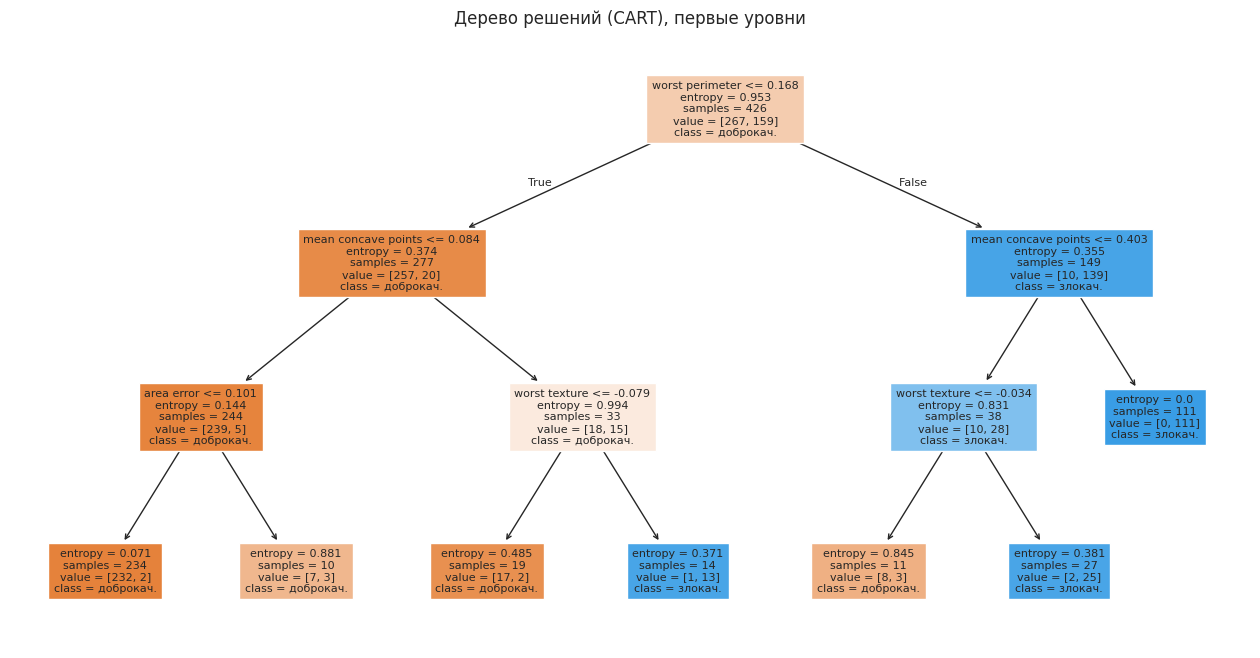

In [ ]:
plt.figure(figsize=(16, 8))
plot_tree(tree, feature_names=selected, class_names=['доброкач.', 'злокач.'], filled=True, fontsize=8, max_depth=3)
plt.title('Дерево решений (CART), первые уровни')
plt.show()

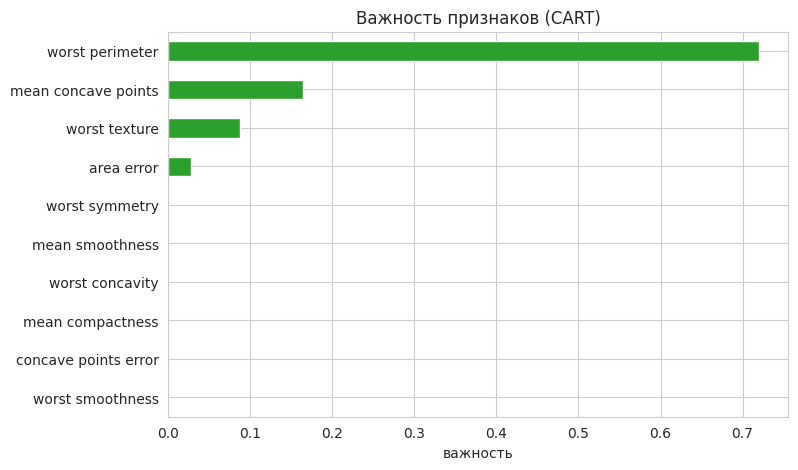

,0
worst perimeter,0.720
mean concave points,0.164
worst texture,0.088
area error,0.028
worst concavity,0.000


In [ ]:
imp = pd.Series(tree.feature_importances_, index=selected).sort_values(ascending=False)
imp.head(10).sort_values().plot(kind='barh', color='tab:green')
plt.title('Важность признаков (CART)')
plt.xlabel('важность')
plt.show()
imp.head(5).round(3)

## 5. Оценка качества моделей

Используемые метрики (положительный класс – злокачественная опухоль):
- **accuracy** – доля верных предсказаний;
- **precision** – какая часть объектов, названных злокачественными, действительно ими является;
- **recall** – какую часть реальных злокачественных опухолей модель нашла (в медицинской задаче пропуск опасного диагноза, т.е. ошибка FN, особенно нежелателен);
- **F1** – среднее гармоническое precision и recall;
- **ROC-AUC** – способность разделять классы при любых порогах.

In [ ]:
rows = []
for name, r in results.items():
    rows.append({'модель': name, **{f'{k}': v for k, v in r['test'].items()},
                 'train accuracy': r['train']['accuracy']})
table = pd.DataFrame(rows).set_index('модель')
table['разрыв acc (train-test)'] = table['train accuracy'] - table['accuracy']
table.round(4)

,accuracy,precision,recall,f1,roc_auc,train accuracy,разрыв acc (train-test)
модель,,,,,,,
LogReg (своя),0.9860,1.0000,0.9623,0.9808,0.9977,0.9836,-0.0024
LogReg (sklearn),0.9790,1.0000,0.9434,0.9709,0.9983,0.9742,-0.0048
SVM (подбор),0.9720,0.9804,0.9434,0.9615,0.9956,0.9953,0.0233
SVM linear (C=1),0.9720,1.0000,0.9245,0.9608,0.9964,0.9812,0.0092
SVM rbf (C=1),0.9720,0.9804,0.9434,0.9615,0.9973,0.9859,0.0139
CART (по умолчанию),0.9301,0.9574,0.8491,0.9000,0.9134,1.0000,0.0699
CART (подбор),0.9301,0.9574,0.8491,0.9000,0.9708,0.9695,0.0394


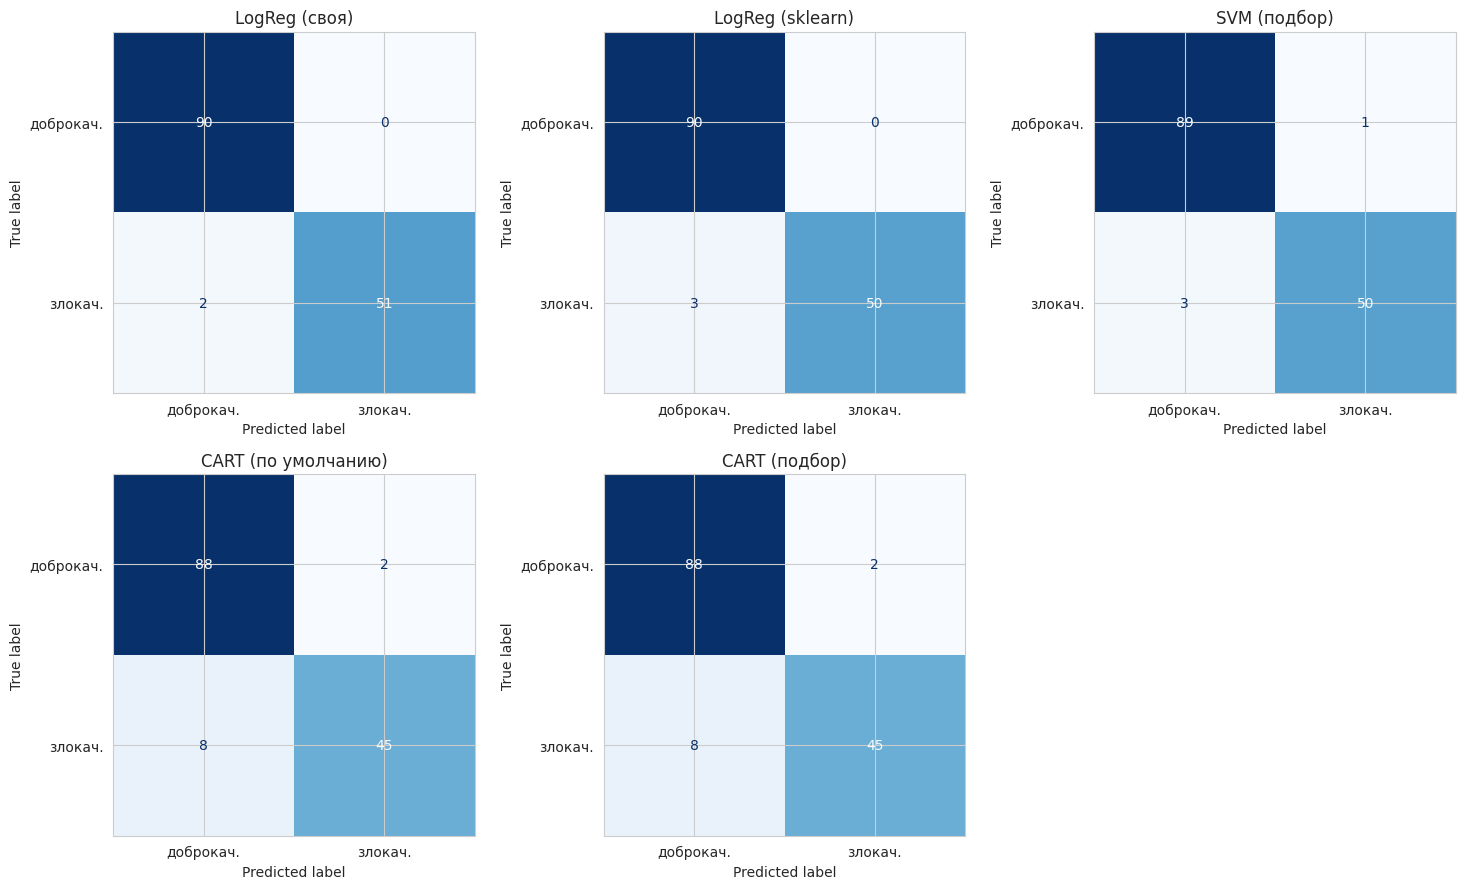

In [ ]:
main_models = ['LogReg (своя)', 'LogReg (sklearn)', 'SVM (подбор)', 'CART (по умолчанию)', 'CART (подбор)']

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, name in zip(axes.ravel(), main_models):
    cm = confusion_matrix(yte, results[name]['y_pred_test'])
    ConfusionMatrixDisplay(cm, display_labels=['доброкач.', 'злокач.']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
axes.ravel()[-1].axis('off')
plt.tight_layout()
plt.show()

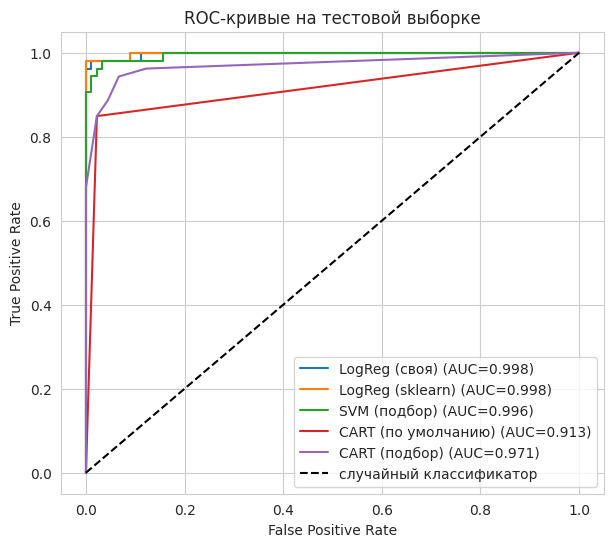

In [ ]:
plt.figure(figsize=(7, 6))
for name in main_models:
    fpr, tpr, _ = roc_curve(yte, results[name]['y_score_test'])
    plt.plot(fpr, tpr, label=f"{name} (AUC={results[name]['test']['roc_auc']:.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='случайный классификатор')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC-кривые на тестовой выборке')
plt.legend(loc='lower right')
plt.show()

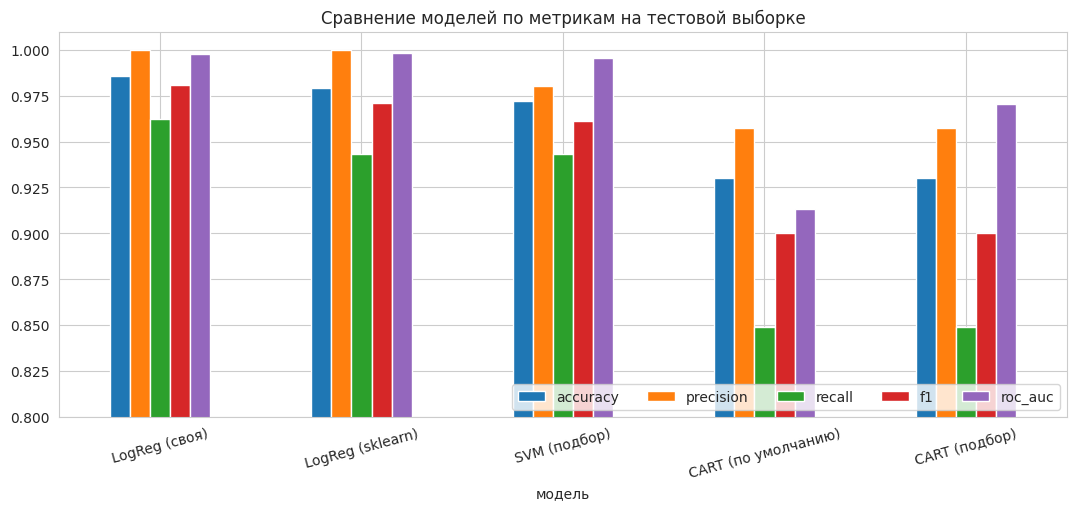

In [ ]:
metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
table.loc[main_models, metrics].plot(kind='bar', figsize=(13, 5), rot=15, ylim=(0.8, 1.01))
plt.title('Сравнение моделей по метрикам на тестовой выборке')
plt.legend(loc='lower right', ncol=5)
plt.show()

In [ ]:
# Устойчивость оценки: F1 по 5-кратной кросс-валидации на обучающей выборке
cv_models = {
    'LogReg (sklearn)': lr,
    'SVM (подбор)': svm,
    'CART (подбор)': tree,
    'CART (по умолчанию)': DecisionTreeClassifier(random_state=RANDOM_STATE),
}
cv_rows = []
for name, model in cv_models.items():
    s = cross_val_score(model, Xtr, ytr, cv=cv, scoring='f1')
    cv_rows.append({'модель': name, 'F1 (CV), среднее': s.mean(), 'F1 (CV), std': s.std()})
pd.DataFrame(cv_rows).set_index('модель').round(4)

,"F1 (CV), среднее","F1 (CV), std"
модель,,
LogReg (sklearn),0.9536,0.0227
SVM (подбор),0.9717,0.0114
CART (подбор),0.9338,0.0303
CART (по умолчанию),0.8952,0.0214


In [ ]:
# Подробный отчёт для лучшей модели по F1 на тесте
best_name = table.loc[main_models].sort_values(['f1', 'roc_auc']).index[-1]
print('Лучшая модель по F1 (при равенстве - по ROC-AUC) на тесте:', best_name)
print(classification_report(yte, results[best_name]['y_pred_test'], target_names=['доброкачественная', 'злокачественная']))

Лучшая модель по F1 (при равенстве - по ROC-AUC) на тесте: LogReg (своя)
                   precision    recall  f1-score   support

доброкачественная       0.98      1.00      0.99        90
  злокачественная       1.00      0.96      0.98        53

         accuracy                           0.99       143
        macro avg       0.99      0.98      0.98       143
     weighted avg       0.99      0.99      0.99       143



## 6. Выводы

**Данные и подготовка.** Использован набор `load_breast_cancer` (569 объектов, 30 числовых признаков), целевая переменная – злокачественность опухоли (37% объектов – положительный класс). Пропусков, дубликатов и категориальных признаков нет. Выбросы (затрагивают 171 из 569 строк) представляют собой реальные крупные опухоли, поэтому строки не удалялись, а значения ограничивались по границам IQR, вычисленным по обучающей выборке. Из групп сильно коррелирующих признаков ($|r| > 0.9$) оставлялся наиболее связанный с целью, в итоге осталось 18 признаков; затем выполнена стандартизация. Все параметры предобработки подбирались только по обучающей выборке, что исключает утечку данных.

**Результаты на тестовой выборке (143 объекта):**

| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Логистическая регрессия (своя) | 0.986 | 1.000 | 0.962 | 0.981 | 0.998 |
| Логистическая регрессия (sklearn, C=0.1) | 0.979 | 1.000 | 0.943 | 0.971 | 0.998 |
| SVM (RBF, C=10, подбор) | 0.972 | 0.980 | 0.943 | 0.962 | 0.996 |
| CART (по умолчанию) | 0.930 | 0.957 | 0.849 | 0.900 | 0.913 |
| CART (подбор: entropy, глубина 3, min_samples_leaf=10) | 0.930 | 0.957 | 0.849 | 0.900 | 0.971 |

1. **Логистическая регрессия и SVM** показали практически одинаковое, очень высокое качество (accuracy 97–99%, ROC-AUC около 0.996–0.998). Классы в этом наборе почти линейно разделимы, поэтому нелинейное ядро RBF не даёт заметного выигрыша: линейный SVM и логистическая регрессия работают не хуже. Собственная реализация логистической регрессии (градиентный спуск, 2000 итераций) даёт качество на уровне `sklearn`; небольшая разница в метриках объясняется тем, что `sklearn` использует L2-регуляризацию (лучшее `C` = 0.1), а своя версия – без регуляризации. Для 5-кратной кросс-валидации по F1 лучше всех SVM (0.972 против 0.954 у логистической регрессии), но различия в пределах разброса.
2. **Дерево решений (CART)** заметно слабее: при параметрах по умолчанию оно идеально запоминает обучающую выборку (accuracy на train = 1.0, глубина 7, 20 листьев) и теряет на тесте (разрыв 7 п.п.), то есть переобучается. Критерии останова (`max_depth=3`, `min_samples_leaf=10`) уменьшили разрыв до 4 п.п., улучшили ROC-AUC (0.913 → 0.971) и F1 по кросс-валидации (0.895 → 0.934) и сделали дерево компактным (7 листьев) и легко интерпретируемым, но по `recall` оно всё равно уступает остальным моделям. Основные признаки дерева – `worst perimeter`, `mean concave points`, `worst texture`.
3. **Ошибки моделей.** В медицинской задаче важнее всего не пропустить злокачественную опухоль (ошибка FN, `recall`). Логистическая регрессия пропустила 2–3 из 53 случаев и не дала ни одного ложного срабатывания, SVM – 3 пропуска и 1 ложное срабатывание, дерево – 8 пропусков и 2 ложных срабатывания. По `recall` дерево заметно хуже.
4. **Оговорка.** Тестовая выборка мала (143 объекта, 53 положительных), поэтому разница между логистической регрессией и SVM – это 1–2 объекта и статистически незначима; уверенно можно утверждать лишь то, что линейные модели и SVM превосходят CART. Для выбора между ними разумнее ориентироваться на кросс-валидацию и требования к интерпретируемости.

**Итог:** для данной задачи наилучшими оказались логистическая регрессия и SVM; логистическая регрессия предпочтительнее благодаря простоте, интерпретируемости весов и калиброванным вероятностям, а дерево решений полезно как наглядная, но менее точная модель, чувствительная к переобучению.